# Proyecto Final — Minería de Datos 1
## Dataset 1: Incidentes atendidos por IA (`ai_agent_incidents`)

**Colegio Universitario de Cartago — Tecnologías de Información, Big Data MD1-152**
Profesor: Ronald Córdoba Vega

**Grupo #1:** Derek Barrantes Torres · Jeriel Eduardo Fonseca Ramírez · Sebastián Flores Figueroa · Jeremy Ramírez Pérez · Samiel Jiménez Portuguez

Este notebook desarrolla los **puntos 1 y 2** del enunciado:

1. Cargar el set de datos y describir los tipos de variables y su uso en el análisis (**diccionario de variables**).
2. Construir la parte exploratoria (**EDA**) y explicarla.

Las conclusiones del final indican qué variables y qué transformaciones se usarán en la clusterización con K-medias (punto 3).

## 1. Librerías y configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

## 2. Carga del set de datos

Cada fila del archivo es un **incidente, investigación, política o reporte relacionado con agentes de IA**, con su tipo de ataque, severidad, región afectada y la fuente que lo documenta.

In [2]:
df = pd.read_csv("ai_agent_incidents.csv")
print(f"Registros: {df.shape[0]}  |  Variables: {df.shape[1]}")
df.head()

Registros: 395  |  Variables: 17


,incident_id,date,year,month,title,attack_type_code,attack_type_name,incident_kind,severity,confidence_level,real_harm_confirmed,ai_involvement,region,is_landmark_event,summary,source_count,primary_source_url
0,2024-12-01-storm-azure-llmjacking,2024-12-01,2024,2024-12,Storm-2139 Azure OpenAI LLMjacking,CRED,Credential & Secret Theft,incident,high,a,True,confirmed,GLOBAL,False,"Microsoft's DCU filed suit in the Eastern District of Virginia in 2024-12 against 10 ""...",1,https://blogs.microsoft.com/on-the-issues/2025/02/27/disrupting-cybercrime-abusing-gen...
1,2025-01-01-maine-town-deepfake-phishing,2025-01-01,2025,2025-01,AI phishing and deepfake voice hit a small Maine town,OTHER,Unclassified AI Incident,incident,medium,a,True,confirmed,US,False,Impersonating town officials to approve tens of thousands of dollars in payments,1,https://genai.owasp.org/2025/03/06/owasp-gen-ai-incident-exploit-round-up-jan-feb-2025/
2,2025-01-20-hk-voice-clone-usdt-fraud,2025-01-20,2025,2025-01,Hong Kong AI voice-clone crypto fraud,OTHER,Unclassified AI Incident,incident,medium,a,True,confirmed,HK,False,Cloned a finance manager's voice; 3 USDT transfers totalling HK$145 million (about US$...,1,https://genai.owasp.org/2025/03/06/owasp-gen-ai-incident-exploit-round-up-jan-feb-2025/
3,2025-01-23-operator-fa-bu-bei-jing,2025-01-23,2025,2025-01,OpenAI Operator launches (context entry),GOV,AI Governance & Policy Failure,policy,info,a,False,confirmed,GLOBAL,False,The first consumer-facing computer-use agent; on 02-01 it opened as a research preview...,1,https://openai.com/index/operator-system-card/
4,2025-01-26-harbin-asian-winter-games-attack,2025-01-26,2025,2025-01,Harbin Asian Winter Games systems attacked,WEAPON,AI Weaponization & Malicious Tooling,incident,high,d,True,disputed,CN,False,National Computer Virus Emergency Response Center report: the Games information system...,1,http://www.news.cn/sports/20250404/9b6d2457ca41488e87ddbe494c2e3ee1/c.html;https://fin...


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   incident_id          395 non-null    str  
 1   date                 395 non-null    str  
 2   year                 395 non-null    int64
 3   month                395 non-null    str  
 4   title                395 non-null    str  
 5   attack_type_code     395 non-null    str  
 6   attack_type_name     395 non-null    str  
 7   incident_kind        395 non-null    str  
 8   severity             395 non-null    str  
 9   confidence_level     395 non-null    str  
 10  real_harm_confirmed  395 non-null    bool 
 11  ai_involvement       395 non-null    str  
 12  region               395 non-null    str  
 13  is_landmark_event    395 non-null    bool 
 14  summary              395 non-null    str  
 15  source_count         395 non-null    int64
 16  primary_source_url   395 non-null    

**Interpretación:** el set tiene **395 registros y 17 variables** y no hay valores nulos. Pandas lee 13 columnas como texto (`str`), 2 como enteros (`year`, `source_count`) y 2 como booleanas. Sin embargo, `date` y `month` son fechas y la mayoría de las columnas de texto son en realidad **categorías**. Por eso el diccionario de la siguiente sección clasifica cada variable por su tipo estadístico y no solo por cómo la lee pandas.

## 3. Diccionario de variables

Para cada variable se indica su **tipo estadístico** (identificador, fecha, categórica nominal u ordinal, booleana, numérica o texto libre), una **descripción** y el **uso** que tendrá en el análisis.

In [4]:
descripcion = {
    "incident_id": ("Identificador", "Identificador único del registro (fecha + nombre corto del caso).",
                    "Solo identifica cada registro; se excluye del análisis."),
    "date": ("Fecha", "Fecha del incidente o de su publicación (AAAA-MM-DD).",
             "Se convierte a fecha para el análisis temporal."),
    "year": ("Numérica discreta (temporal)", "Año del registro (2024–2026).",
             "Análisis temporal; es redundante con date."),
    "month": ("Categórica ordinal (temporal)", "Año y mes del registro (AAAA-MM).",
              "Agrupar la serie mensual; es redundante con date."),
    "title": ("Texto libre", "Título breve del caso (en inglés).",
              "Solo descriptiva; se excluye del modelado."),
    "attack_type_code": ("Categórica nominal multietiqueta",
                         "Código de la familia de ataque. Puede combinar varias familias separadas por ';' (p. ej. IPI;EXFIL).",
                         "Se separa en 12 variables binarias, una por familia de ataque."),
    "attack_type_name": ("Categórica nominal", "Nombre de la familia de ataque; en las combinaciones repite el código.",
                         "Redundante con attack_type_code; solo para etiquetas."),
    "incident_kind": ("Categórica nominal", "Naturaleza del registro: incident, research, policy, vulnerability o report.",
                      "Variable clave del EDA; candidata para la clusterización (codificación one-hot)."),
    "severity": ("Categórica ordinal", "Severidad del caso, de menor a mayor: info, low, medium, high, critical.",
                 "Variable clave; se codifica de 0 (info) a 4 (critical)."),
    "confidence_level": ("Categórica ordinal", "Nivel de confianza de la información, de 'a' (mayor) a 'd' (menor).",
                         "Se codifica de 4 (a) a 1 (d); se revisa su variabilidad."),
    "real_harm_confirmed": ("Booleana", "Indica si se confirmó un daño real.",
                            "Variable clave; se codifica como 1/0."),
    "ai_involvement": ("Categórica nominal", "Grado de participación de la IA: confirmed, disputed, unverified o not-applicable.",
                       "Se revisa su variabilidad antes de decidir si se usa."),
    "region": ("Categórica nominal multietiqueta", "Región o regiones afectadas (GLOBAL, US, CN, EU…), separadas por ';'.",
               "Se resume en 'es_global' y en la cantidad de regiones."),
    "is_landmark_event": ("Booleana", "Indica si el caso se considera un evento emblemático (hito).",
                          "Se codifica como 1/0; candidata para la clusterización."),
    "summary": ("Texto libre", "Resumen del caso en inglés.",
                "Se excluye del modelado numérico; se usa su longitud como variable derivada."),
    "source_count": ("Numérica discreta", "Cantidad de fuentes citadas.",
                     "Se revisa si es constante; en ese caso se elimina."),
    "primary_source_url": ("Texto (URL)", "Enlace a la fuente principal.",
                           "Se extrae el dominio para describir las fuentes; se excluye del modelado."),
}

diccionario = pd.DataFrame(
    [(col, descripcion[col][0], str(df[col].dtype), df[col].nunique(), descripcion[col][1], descripcion[col][2])
     for col in df.columns],
    columns=["Variable", "Tipo estadístico", "Tipo en pandas", "Valores únicos", "Descripción", "Uso en el análisis"],
)
diccionario.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"})

Variable,Tipo estadístico,Tipo en pandas,Valores únicos,Descripción,Uso en el análisis
incident_id,Identificador,str,395,Identificador único del registro (fecha + nombre corto del caso).,Solo identifica cada registro; se excluye del análisis.
date,Fecha,str,241,Fecha del incidente o de su publicación (AAAA-MM-DD).,Se convierte a fecha para el análisis temporal.
year,Numérica discreta (temporal),int64,3,Año del registro (2024–2026).,Análisis temporal; es redundante con date.
month,Categórica ordinal (temporal),str,23,Año y mes del registro (AAAA-MM).,Agrupar la serie mensual; es redundante con date.
title,Texto libre,str,395,Título breve del caso (en inglés).,Solo descriptiva; se excluye del modelado.
attack_type_code,Categórica nominal multietiqueta,str,55,Código de la familia de ataque. Puede combinar varias familias separadas por ';' (p. ej. IPI;EXFIL).,"Se separa en 12 variables binarias, una por familia de ataque."
attack_type_name,Categórica nominal,str,55,Nombre de la familia de ataque; en las combinaciones repite el código.,Redundante con attack_type_code; solo para etiquetas.
incident_kind,Categórica nominal,str,5,"Naturaleza del registro: incident, research, policy, vulnerability o report.",Variable clave del EDA; candidata para la clusterización (codificación one-hot).
severity,Categórica ordinal,str,5,"Severidad del caso, de menor a mayor: info, low, medium, high, critical.",Variable clave; se codifica de 0 (info) a 4 (critical).
confidence_level,Categórica ordinal,str,4,"Nivel de confianza de la información, de 'a' (mayor) a 'd' (menor).",Se codifica de 4 (a) a 1 (d); se revisa su variabilidad.


In [5]:
diccionario["Tipo estadístico"].value_counts().to_frame("Cantidad de variables")

,Cantidad de variables
Tipo estadístico,
Categórica nominal,3
Texto libre,2
Categórica nominal multietiqueta,2
Categórica ordinal,2
Booleana,2
Identificador,1
Fecha,1
Numérica discreta (temporal),1
Categórica ordinal (temporal),1


**Lectura del diccionario:**

- Es un set **predominantemente categórico**: solo `year` y `source_count` son numéricas, y ninguna es una medición continua.
- Las variables con más valor analítico son `incident_kind`, `severity`, `real_harm_confirmed`, `is_landmark_event` y las familias de ataque (`attack_type_code`).
- `incident_id`, `title`, `summary` y `primary_source_url` son únicas (o casi) en cada registro: sirven para identificar y describir casos, pero no para encontrar patrones.
- Hay variables redundantes: `attack_type_name` repite la información de `attack_type_code`, y `year` y `month` repiten la de `date`.
- K-medias trabaja con distancias numéricas, así que las variables categóricas deberán **codificarse** (ordinal o one-hot) y **escalarse** antes de agrupar.

## 4. Calidad de los datos

Se revisan valores nulos, registros duplicados, variables constantes y la coherencia entre las columnas de fecha.

In [6]:
calidad = pd.DataFrame({
    "Nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "Valores únicos": df.nunique(),
    "% únicos": (df.nunique() / len(df) * 100).round(1),
})
print("Filas duplicadas:", df.duplicated().sum())
print("IDs repetidos:", df["incident_id"].duplicated().sum())
print("Variables constantes:", calidad.index[calidad["Valores únicos"] == 1].tolist())
print("month coincide con date:", (df["date"].str[:7] == df["month"]).all())
print("year coincide con date:", (df["date"].str[:4].astype(int) == df["year"]).all())
print("Rango de fechas:", df["date"].min(), "a", df["date"].max())
calidad

Filas duplicadas: 0
IDs repetidos: 0
Variables constantes: ['source_count']
month coincide con date: True
year coincide con date: True
Rango de fechas: 2024-12-01 a 2026-10-09


,Nulos,% nulos,Valores únicos,% únicos
incident_id,0,0.0,395,100.0
date,0,0.0,241,61.0
year,0,0.0,3,0.8
month,0,0.0,23,5.8
title,0,0.0,395,100.0
attack_type_code,0,0.0,55,13.9
attack_type_name,0,0.0,55,13.9
incident_kind,0,0.0,5,1.3
severity,0,0.0,5,1.3
confidence_level,0,0.0,4,1.0


**Interpretación:**

- **No hay valores nulos ni registros duplicados**, y cada `incident_id` es único.
- `source_count` es **constante** (siempre vale 1): no aporta información y se elimina.
- `month` y `year` coinciden con `date` en el 100% de los registros.
- Los datos van del **1 de diciembre de 2024 al 9 de octubre de 2026**; octubre de 2026 es un mes incompleto.
- `attack_type_code` tiene 55 combinaciones distintas para solo 395 registros, por lo que hay que reorganizarla (sección 5).
- `primary_source_url` tiene 353 valores distintos: algunas fuentes documentan más de un caso.

## 5. Limpieza y preparación

Se trabaja sobre una copia (`datos`) para conservar el archivo original. Las transformaciones son:

| Transformación | Motivo |
|---|---|
| `date` a tipo fecha | Permite agrupar por mes y ordenar en el tiempo. |
| Eliminar `source_count` | Es constante (todas las filas valen 1), así que no aporta información. |
| `severity` → `severidad_ord` (0–4) | Es ordinal: el orden *info < low < medium < high < critical* tiene significado. |
| `confidence_level` → `confianza_ord` (4–1) | Es ordinal: *a* es la mayor confianza y *d* la menor. |
| Booleanas → 0/1 (`daño_real`, `evento_hito`) | Formato numérico para correlaciones y para K-medias. |
| `attack_type_code` → 12 columnas `fam_*` | Un incidente puede pertenecer a varias familias de ataque a la vez. |
| `region` → `es_global` y `n_regiones` | Hay 19 combinaciones de regiones y la mayoría de los casos son globales. |
| Dominio de la URL y largo del resumen | Variables derivadas para describir las fuentes y el nivel de detalle. |

In [7]:
datos = df.copy()
datos["date"] = pd.to_datetime(datos["date"])
datos = datos.drop(columns=["source_count"])

orden_severidad = ["info", "low", "medium", "high", "critical"]
datos["severidad_ord"] = datos["severity"].map({s: i for i, s in enumerate(orden_severidad)})
datos["confianza_ord"] = datos["confidence_level"].map({"a": 4, "b": 3, "c": 2, "d": 1})
datos["daño_real"] = datos["real_harm_confirmed"].astype(int)
datos["evento_hito"] = datos["is_landmark_event"].astype(int)

familias = datos["attack_type_code"].str.get_dummies(sep=";")
datos = pd.concat([datos, familias.add_prefix("fam_")], axis=1)
datos["n_familias"] = familias.sum(axis=1)

regiones = datos["region"].str.get_dummies(sep=";")
datos["es_global"] = regiones["GLOBAL"]
datos["n_regiones"] = regiones.sum(axis=1)

datos["dominio_fuente"] = datos["primary_source_url"].str.extract(r"https?://(?:www\.)?([^/]+)")[0]
datos["largo_resumen"] = datos["summary"].str.len()

print("Forma después de la preparación:", datos.shape)
datos[["severity", "severidad_ord", "confidence_level", "confianza_ord", "attack_type_code",
       "n_familias", "region", "es_global", "n_regiones", "dominio_fuente", "largo_resumen"]].head()

Forma después de la preparación: (395, 37)


,severity,severidad_ord,confidence_level,confianza_ord,attack_type_code,n_familias,region,es_global,n_regiones,dominio_fuente,largo_resumen
0,high,3,a,4,CRED,1,GLOBAL,1,1,blogs.microsoft.com,285
1,medium,2,a,4,OTHER,1,US,0,1,genai.owasp.org,80
2,medium,2,a,4,OTHER,1,HK,0,1,genai.owasp.org,92
3,info,0,a,4,GOV,1,GLOBAL,1,1,openai.com,355
4,high,3,d,1,WEAPON,1,CN,0,1,news.cn,556


In [8]:
nombres_familias = {
    "CRED": "Robo de credenciales y secretos",
    "EVAL": "Envenenamiento de evaluaciones",
    "EXFIL": "Exfiltración de datos o modelos",
    "GOV": "Falla de gobernanza o política",
    "INFRA": "Compromiso de infraestructura",
    "IPI": "Inyección indirecta de prompts",
    "MCP": "Explotación de MCP",
    "OTHER": "No clasificado",
    "ROGUE": "Agente autónomo fuera de control",
    "SANDBOX": "Escape de sandbox",
    "SUPPLY": "Cadena de suministro",
    "WEAPON": "IA usada como arma",
}
pd.DataFrame({"Familia": nombres_familias}).rename_axis("Código")

,Familia
Código,
CRED,Robo de credenciales y secretos
EVAL,Envenenamiento de evaluaciones
EXFIL,Exfiltración de datos o modelos
GOV,Falla de gobernanza o política
INFRA,Compromiso de infraestructura
IPI,Inyección indirecta de prompts
MCP,Explotación de MCP
OTHER,No clasificado
ROGUE,Agente autónomo fuera de control


## 6. Análisis exploratorio (EDA)

### 6.1 Distribución de las variables categóricas principales

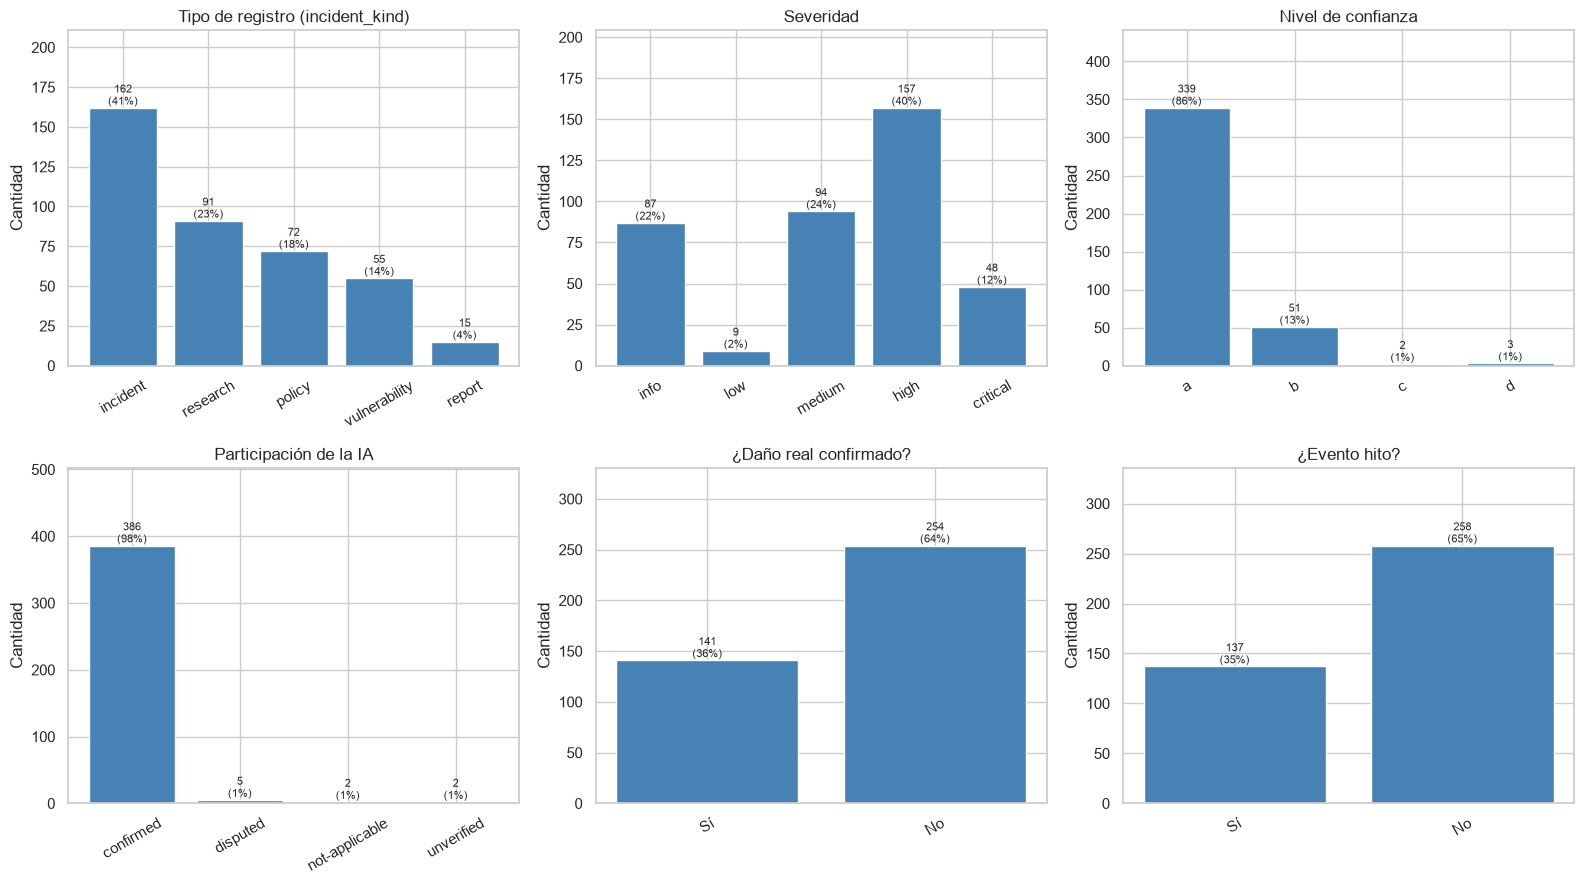

In [9]:
def barras_con_porcentaje(serie, titulo, ax, orden=None):
    conteo = serie.value_counts()
    if orden is not None:
        conteo = conteo.reindex(orden, fill_value=0)
    ax.bar(conteo.index.astype(str), conteo.values, color="steelblue")
    total = conteo.sum()
    for i, valor in enumerate(conteo.values):
        ax.text(i, valor, f"{valor}\n({valor / total:.0%})", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, conteo.max() * 1.3)
    ax.set_title(titulo)
    ax.set_ylabel("Cantidad")
    ax.tick_params(axis="x", rotation=30)


si_no = {True: "Sí", False: "No"}
fig, ejes = plt.subplots(2, 3, figsize=(16, 9))
barras_con_porcentaje(datos["incident_kind"], "Tipo de registro (incident_kind)", ejes[0, 0])
barras_con_porcentaje(datos["severity"], "Severidad", ejes[0, 1], orden=orden_severidad)
barras_con_porcentaje(datos["confidence_level"], "Nivel de confianza", ejes[0, 2], orden=["a", "b", "c", "d"])
barras_con_porcentaje(datos["ai_involvement"], "Participación de la IA", ejes[1, 0])
barras_con_porcentaje(datos["real_harm_confirmed"].map(si_no), "¿Daño real confirmado?", ejes[1, 1], orden=["Sí", "No"])
barras_con_porcentaje(datos["is_landmark_event"].map(si_no), "¿Evento hito?", ejes[1, 2], orden=["Sí", "No"])
plt.tight_layout()
plt.show()

**Interpretación:**

- **Tipo de registro:** solo el 41% son incidentes reales. El resto son investigaciones (23%), políticas (18%), vulnerabilidades (14%) y reportes (4%). Es decir, casi 6 de cada 10 registros documentan **contexto** (estudios, políticas o fallas descubiertas) y no ataques consumados.
- **Severidad:** predomina `high` (40%). La categoría `low` casi no existe (9 casos, 2%), así que la escala está cargada hacia las severidades media y alta.
- **Nivel de confianza:** el 86% tiene confianza `a` y solo 5 casos tienen `c` o `d`. Tiene poca variabilidad, así que aportará poco para diferenciar grupos.
- **Participación de la IA:** el 98% es `confirmed`. Es prácticamente **constante**, por lo que se descarta para K-medias.
- **Daño real y evento hito:** cada una está presente en cerca de un tercio de los casos (36% y 35%). Ese balance las hace útiles como variables binarias.

### 6.2 Familias de ataque

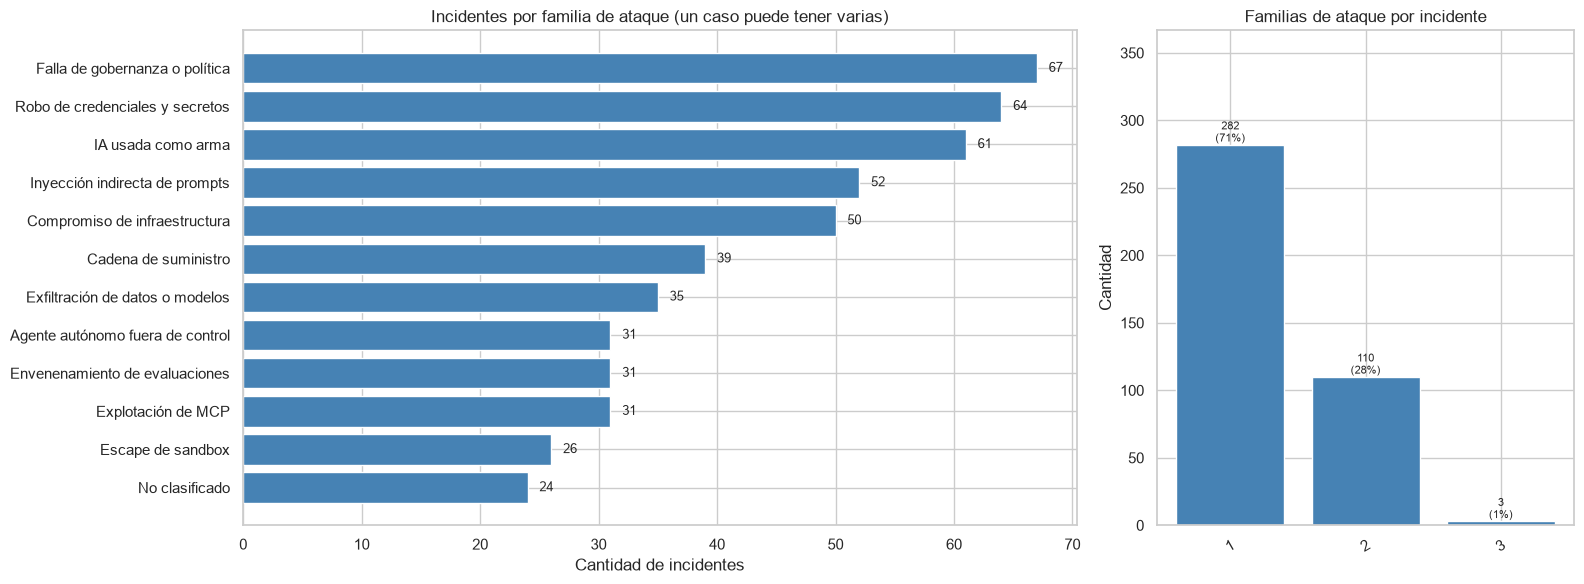

Combinaciones distintas de attack_type_code: 55
Combinaciones con 3 casos o menos: 39


In [10]:
frecuencia_familias = familias.sum().rename(index=nombres_familias).sort_values()

fig, ejes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2, 1]})
ejes[0].barh(frecuencia_familias.index, frecuencia_familias.values, color="steelblue")
for i, valor in enumerate(frecuencia_familias.values):
    ejes[0].text(valor + 1, i, str(valor), va="center", fontsize=9)
ejes[0].set_title("Incidentes por familia de ataque (un caso puede tener varias)")
ejes[0].set_xlabel("Cantidad de incidentes")

barras_con_porcentaje(datos["n_familias"], "Familias de ataque por incidente", ejes[1], orden=[1, 2, 3])
plt.tight_layout()
plt.show()

print("Combinaciones distintas de attack_type_code:", df["attack_type_code"].nunique())
print("Combinaciones con 3 casos o menos:", (df["attack_type_code"].value_counts() <= 3).sum())

**Interpretación:**

- Las familias más frecuentes son **fallas de gobernanza o política (67)**, **robo de credenciales (64)** e **IA usada como arma (61)**. Ninguna domina: la más común aparece en el 17% de los registros.
- El **71%** de los registros tiene una sola familia, el **28%** combina dos y solo 3 casos combinan tres.
- Las 55 combinaciones originales de `attack_type_code` son demasiadas para 395 registros (39 de ellas tienen 3 casos o menos). Separarlas en **12 columnas binarias** conserva toda la información sin crear categorías casi vacías.

### 6.3 Regiones afectadas y fuentes

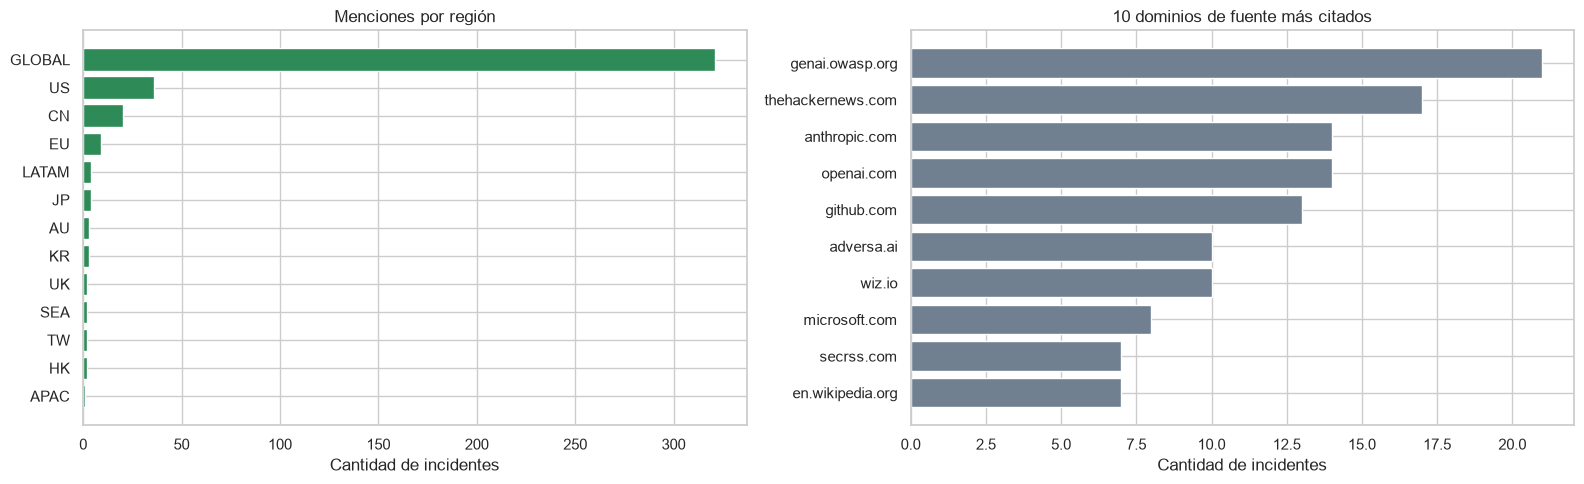

Casos globales: 81.3%
Casos con más de una región: 3.5%
Dominios de fuente distintos: 183


In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
frecuencia_regiones = regiones.sum().sort_values()
ejes[0].barh(frecuencia_regiones.index, frecuencia_regiones.values, color="seagreen")
ejes[0].set_title("Menciones por región")
ejes[0].set_xlabel("Cantidad de incidentes")

top_dominios = datos["dominio_fuente"].value_counts().head(10).sort_values()
ejes[1].barh(top_dominios.index, top_dominios.values, color="slategray")
ejes[1].set_title("10 dominios de fuente más citados")
ejes[1].set_xlabel("Cantidad de incidentes")
plt.tight_layout()
plt.show()

print(f"Casos globales: {datos['es_global'].mean():.1%}")
print(f"Casos con más de una región: {(datos['n_regiones'] > 1).mean():.1%}")
print(f"Dominios de fuente distintos: {datos['dominio_fuente'].nunique()}")

**Interpretación:**

- El **81%** de los casos tiene alcance `GLOBAL`. Le siguen Estados Unidos (36 casos) y China (20); el resto de las regiones aparece en muy pocos casos.
- Solo el 3.5% de los casos menciona más de una región, así que `n_regiones` casi no varía.
- Las fuentes están muy repartidas (**183 dominios distintos**). Las más citadas son OWASP GenAI, The Hacker News y los sitios oficiales de Anthropic y OpenAI: fuentes técnicas y de los propios fabricantes de IA.
- Como la región está tan concentrada en `GLOBAL`, distingue poco entre casos. A lo sumo se usará la variable binaria `es_global`.

### 6.4 Evolución en el tiempo

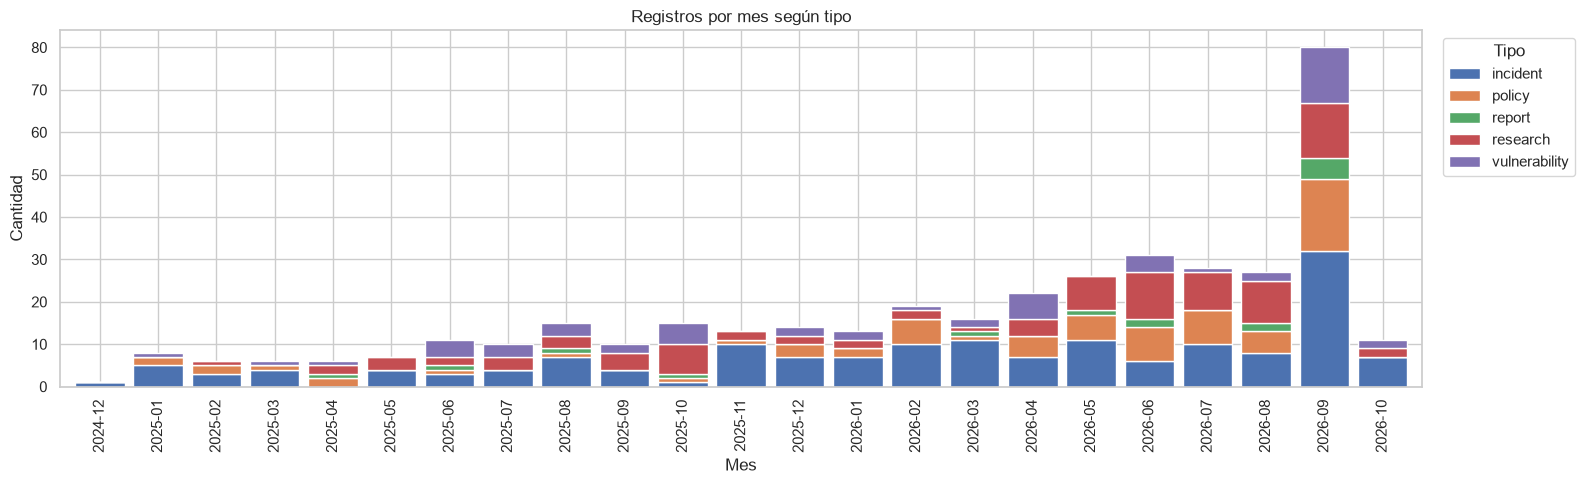

Registros por año:
year
2024      1
2025    121
2026    273
Último registro: 2026-10-09


In [12]:
mensual = pd.crosstab(datos["date"].dt.to_period("M"), datos["incident_kind"])
mensual.index = mensual.index.astype(str)

ax = mensual.plot(kind="bar", stacked=True, figsize=(16, 5), width=0.85)
ax.set_title("Registros por mes según tipo")
ax.set_xlabel("Mes")
ax.set_ylabel("Cantidad")
ax.legend(title="Tipo", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Registros por año:")
print(datos["year"].value_counts().sort_index().to_string())
print("Último registro:", datos["date"].max().date())

**Interpretación:**

- Hay **1 registro en 2024, 121 en 2025 y 273 en 2026** (hasta el 9 de octubre). La cantidad crece de forma sostenida, con un pico muy marcado en **septiembre de 2026 (80 registros)**.
- El crecimiento puede deberse a un aumento real de incidentes con agentes de IA, pero también a un **sesgo de recolección**: en un set construido a partir de noticias y reportes, los meses recientes suelen estar mejor documentados. Además, octubre de 2026 está incompleto.
- En la mayoría de los meses el tipo más común es `incident`, aunque hay meses dominados por investigaciones (por ejemplo, junio de 2026).
- Con solo 23 meses y un pico atípico, la serie es **demasiado corta para pronosticar** ataques futuros de forma confiable.

### 6.5 Relaciones entre variables

#### Severidad frente a daño real y evento hito

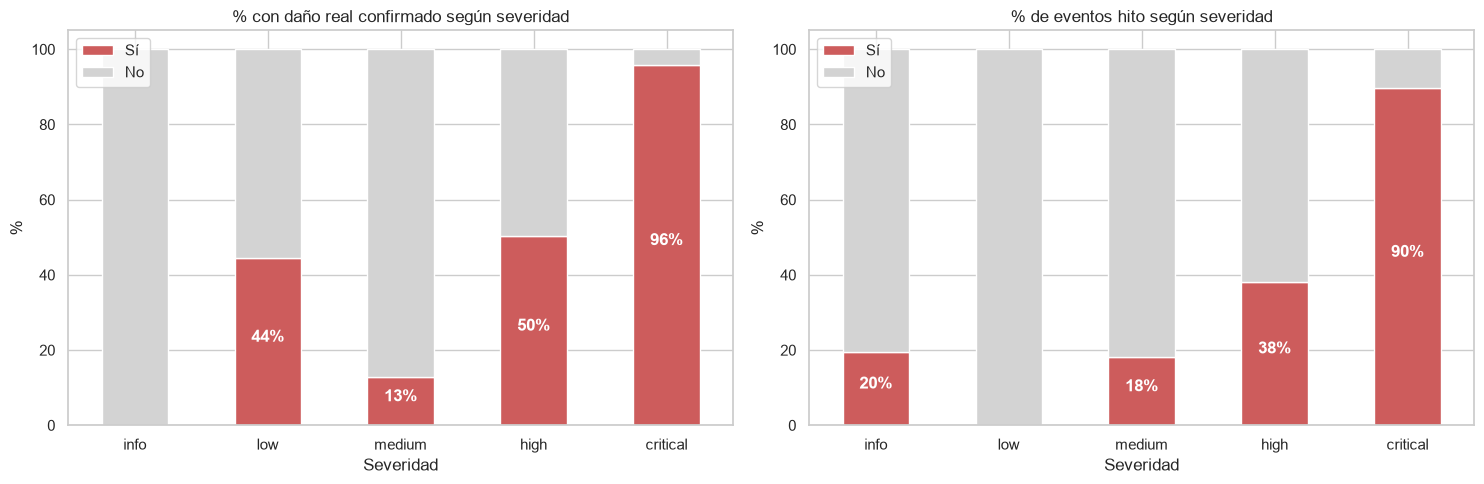

real_harm_confirmed,No,Sí,Total
severity,,,
info,87,0,87
low,5,4,9
medium,82,12,94
high,78,79,157
critical,2,46,48
Total,254,141,395


In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for ax, columna, titulo in [
    (ejes[0], "real_harm_confirmed", "% con daño real confirmado según severidad"),
    (ejes[1], "is_landmark_event", "% de eventos hito según severidad"),
]:
    tabla = pd.crosstab(datos["severity"], datos[columna].map(si_no), normalize="index").reindex(orden_severidad) * 100
    tabla[["Sí", "No"]].plot(kind="bar", stacked=True, ax=ax, color=["indianred", "lightgray"], rot=0)
    for i, valor in enumerate(tabla["Sí"]):
        if valor > 5:
            ax.text(i, valor / 2, f"{valor:.0f}%", ha="center", color="white", fontweight="bold")
    ax.set_title(titulo)
    ax.set_xlabel("Severidad")
    ax.set_ylabel("%")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

pd.crosstab(datos["severity"], datos["real_harm_confirmed"].map(si_no), margins=True, margins_name="Total").reindex(orden_severidad + ["Total"])

**Interpretación:**

- La relación entre severidad y daño real es **muy fuerte**: el 96% de los casos `critical` tiene daño real confirmado, frente al 50% de los `high`, el 13% de los `medium` y el **0% de los `info`**.
- Los eventos hito también se concentran en los casos críticos (90%) y altos (38%).
- `low` tiene solo 9 casos, así que su 44% de daño real no es representativo.
- Juntas, `severity`, `real_harm_confirmed` e `is_landmark_event` describen el **impacto** de un caso. Probablemente serán las variables que más separen los grupos en K-medias.

#### Tipo de registro frente a severidad

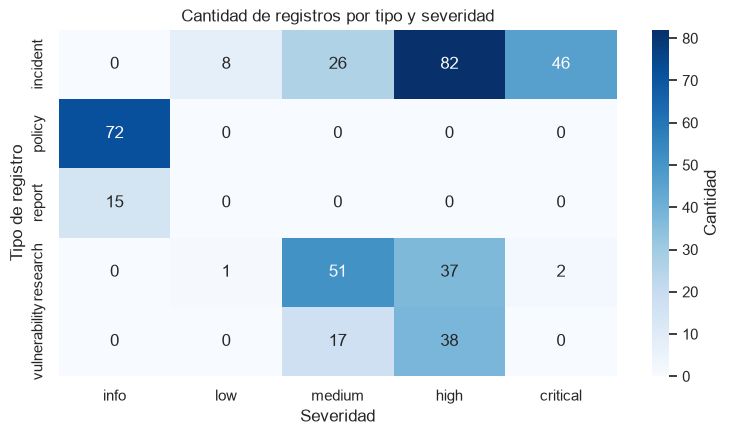

In [14]:
tabla_tipo = pd.crosstab(datos["incident_kind"], datos["severity"])[orden_severidad]
plt.figure(figsize=(9, 4.5))
sns.heatmap(tabla_tipo, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Cantidad"})
plt.title("Cantidad de registros por tipo y severidad")
plt.xlabel("Severidad")
plt.ylabel("Tipo de registro")
plt.show()

**Interpretación:**

- La severidad `info` corresponde **exactamente** a los registros `policy` (72) y `report` (15). Ningún incidente, investigación o vulnerabilidad tiene severidad `info`, y ninguna política o reporte tiene otra severidad.
- De los 48 casos `critical`, 46 son incidentes reales.
- Las investigaciones (`research`) se reparten sobre todo entre `medium` y `high`, y las vulnerabilidades son mayormente `high`.
- **Implicación:** `incident_kind` y `severity` se repiten en parte (saber que un registro es `policy` ya dice que su severidad es `info`). Si se usan juntas en K-medias, ese bloque pesará más en la distancia, y hay que tenerlo en cuenta al interpretar los grupos.

#### Perfil de cada familia de ataque

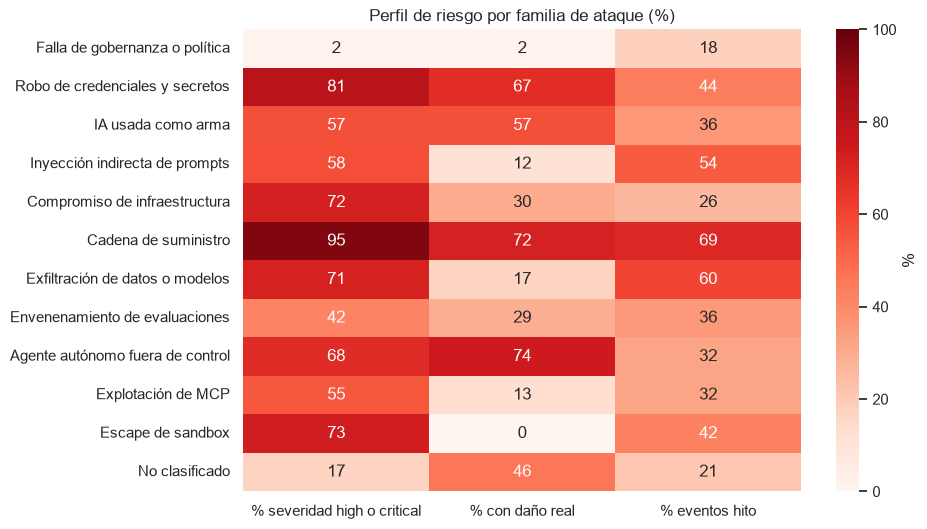

,Casos,% severidad high o critical,% con daño real,% eventos hito
Falla de gobernanza o política,67,1.5,1.5,17.9
Robo de credenciales y secretos,64,81.2,67.2,43.8
IA usada como arma,61,57.4,57.4,36.1
Inyección indirecta de prompts,52,57.7,11.5,53.8
Compromiso de infraestructura,50,72.0,30.0,26.0
Cadena de suministro,39,94.9,71.8,69.2
Exfiltración de datos o modelos,35,71.4,17.1,60.0
Envenenamiento de evaluaciones,31,41.9,29.0,35.5
Agente autónomo fuera de control,31,67.7,74.2,32.3
Explotación de MCP,31,54.8,12.9,32.3


In [15]:
perfil_familias = pd.DataFrame({
    "Casos": familias.sum(),
    "% severidad high o critical": [datos.loc[familias[f] == 1, "severidad_ord"].ge(3).mean() * 100 for f in familias],
    "% con daño real": [datos.loc[familias[f] == 1, "daño_real"].mean() * 100 for f in familias],
    "% eventos hito": [datos.loc[familias[f] == 1, "evento_hito"].mean() * 100 for f in familias],
}).rename(index=nombres_familias).sort_values("Casos", ascending=False).round(1)

plt.figure(figsize=(9, 6))
sns.heatmap(perfil_familias.drop(columns="Casos"), annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "%"})
plt.title("Perfil de riesgo por familia de ataque (%)")
plt.ylabel("")
plt.show()
perfil_familias

**Interpretación:**

- Las familias con **más impacto** son **cadena de suministro** (95% de severidad alta o crítica y 72% con daño real), **robo de credenciales** (81% y 67%) y **agente autónomo fuera de control** (68% y 74%).
- **Escape de sandbox**, **inyección indirecta de prompts** y **explotación de MCP** suelen tener severidad alta, pero casi nunca daño real (0%, 12% y 13%). Esto se explica porque son en su mayoría investigaciones y vulnerabilidades demostradas en laboratorio, no ataques consumados (por ejemplo, 25 de los 26 casos de sandbox son `research` o `vulnerability`).
- **Fallas de gobernanza o política** casi nunca son graves (1.5%), porque son sobre todo registros de tipo `policy`.
- Cada familia tiene un perfil de riesgo distinto, por lo que las columnas `fam_*` son buenas candidatas para la clusterización.

#### Familias de ataque que aparecen juntas

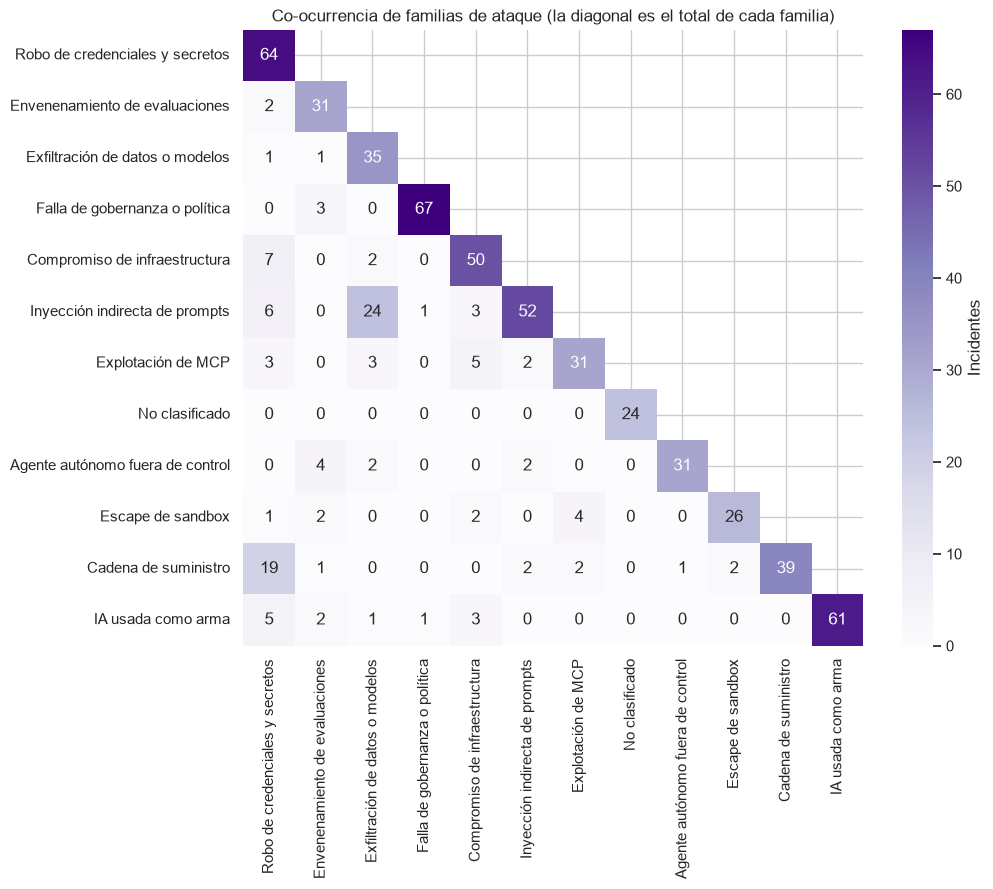

In [16]:
coocurrencia = (familias.T @ familias).rename(index=nombres_familias, columns=nombres_familias)
mascara = np.triu(np.ones_like(coocurrencia, dtype=bool), k=1)
plt.figure(figsize=(10, 8))
sns.heatmap(coocurrencia, mask=mascara, annot=True, fmt="d", cmap="Purples", cbar_kws={"label": "Incidentes"})
plt.title("Co-ocurrencia de familias de ataque (la diagonal es el total de cada familia)")
plt.show()

**Interpretación:**

- La mayoría de las familias aparecen solas. Las combinaciones más frecuentes son:
  - **Inyección indirecta de prompts + exfiltración** (24 casos): la inyección de instrucciones se usa para robar datos.
  - **Cadena de suministro + robo de credenciales** (19 casos): paquetes o dependencias comprometidas que roban secretos.
  - **Infraestructura + credenciales** (7) e **inyección de prompts + credenciales** (6).
- Estas combinaciones tienen sentido técnico: algunas familias funcionan como **etapas de un mismo ataque** (primero se entra y después se roba).

#### Correlación entre las variables codificadas

Se usa la correlación de **Spearman**, adecuada para variables ordinales y binarias como las de este set de datos.

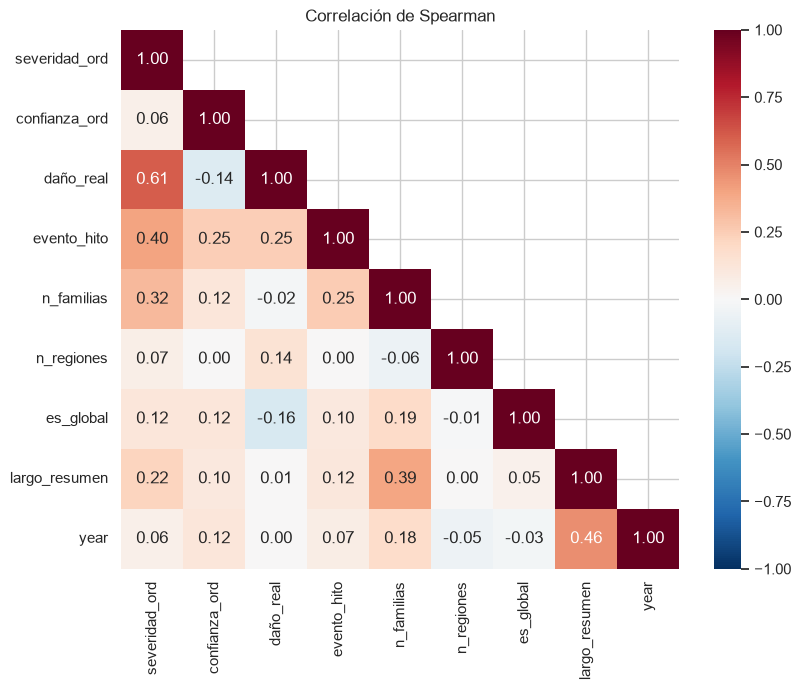

In [17]:
variables_numericas = ["severidad_ord", "confianza_ord", "daño_real", "evento_hito",
                       "n_familias", "n_regiones", "es_global", "largo_resumen", "year"]
correlacion = datos[variables_numericas].corr(method="spearman")
mascara = np.triu(np.ones_like(correlacion, dtype=bool), k=1)
plt.figure(figsize=(9, 7))
sns.heatmap(correlacion, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación de Spearman")
plt.show()

**Interpretación:**

- La correlación más fuerte es entre **severidad y daño real (0.61)**, seguida por **severidad y evento hito (0.40)**. Esto confirma lo visto en las tablas cruzadas.
- `n_familias` se relaciona con la severidad (0.32) y con el largo del resumen (0.39): los ataques que combinan varias técnicas suelen ser más graves y se describen con más detalle.
- `largo_resumen` está correlacionado con `year` (0.46): los registros más recientes tienen resúmenes más largos. Esto refleja cómo se construyó el set, no una característica de los ataques.
- La confianza, `es_global` y `n_regiones` tienen correlaciones bajas con todo lo demás.
- No hay correlaciones extremas (mayores a 0.8), así que ninguna de estas variables es totalmente redundante.

#### Nivel de detalle del resumen según severidad

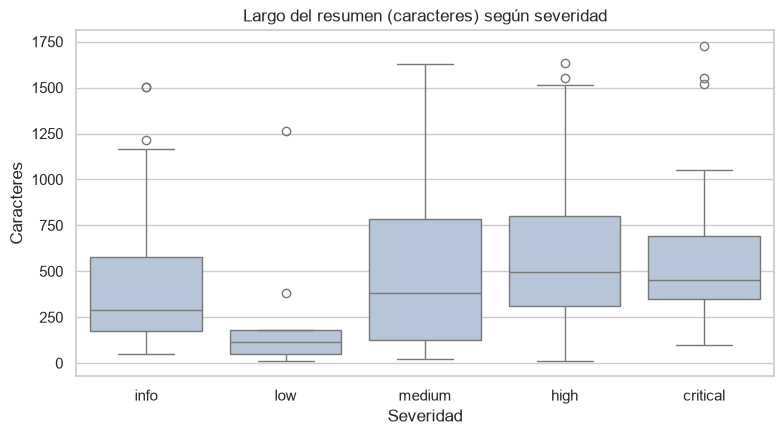

,Mediana de caracteres
severity,
info,288.0
low,116.0
medium,383.5
high,497.0
critical,451.0


In [18]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=datos, x="severity", y="largo_resumen", order=orden_severidad, color="lightsteelblue")
plt.title("Largo del resumen (caracteres) según severidad")
plt.xlabel("Severidad")
plt.ylabel("Caracteres")
plt.show()
datos.groupby("severity")["largo_resumen"].median().reindex(orden_severidad).to_frame("Mediana de caracteres")

**Interpretación:**

- Los casos `high` y `critical` tienen los resúmenes más largos (medianas de 497 y 451 caracteres), y los `low` los más cortos (116).
- La diferencia es moderada y, como se vio en la correlación, el largo del resumen depende más del año del registro que de la severidad. Por eso **no se usará `largo_resumen` en la clusterización**: describe cómo se documentó el caso, no el caso en sí.

## 7. Conclusiones del EDA

### Hallazgos principales

1. **Datos limpios:** 395 registros sin nulos ni duplicados. Solo hubo que eliminar `source_count`, que es constante.
2. **Set casi totalmente categórico:** no hay mediciones numéricas continuas. Las variables útiles son categóricas, ordinales o binarias, y deben codificarse antes de aplicar K-medias.
3. **El impacto se concentra en pocas variables:** severidad, daño real y evento hito están relacionadas (Spearman de 0.61 y 0.40). El 96% de los casos críticos tiene daño real confirmado.
4. **Hay un bloque redundante:** la severidad `info` equivale exactamente a los registros `policy` y `report`.
5. **Las familias de ataque tienen perfiles de riesgo distintos:** cadena de suministro, credenciales y agentes fuera de control son las más dañinas; sandbox, MCP e inyección de prompts son graves pero rara vez causan daño confirmado, porque son sobre todo investigaciones.
6. **Variables con poca información:** `ai_involvement` (98% `confirmed`), `confidence_level` (86% `a`) y la región (81% `GLOBAL`).
7. **La serie temporal es corta y creciente**, con un pico en septiembre de 2026 que probablemente refleja la forma en que se recolectaron los datos.

### Implicaciones para la clusterización con K-medias

| Decisión | Variables |
|---|---|
| **Usar** (codificadas y escaladas) | `severidad_ord`, `daño_real`, `evento_hito`, `incident_kind` (one-hot), las 12 columnas `fam_*`, `n_familias` |
| **Evaluar** (poca variabilidad) | `confianza_ord`, `es_global` |
| **Excluir** | `incident_id`, `title`, `summary`, `primary_source_url`, `attack_type_name`, `ai_involvement`, `source_count`, columnas de fecha, `largo_resumen` |

- Todas las variables se **escalarán** (por ejemplo con `StandardScaler`) para que ninguna domine la distancia.
- La cantidad de grupos (*k*) se elegirá con el **método del codo** y el **coeficiente de silueta**.
- Como casi todas las variables son binarias, los grupos se validarán también por su interpretación (qué tipo de caso representa cada uno) y no solo por las métricas.